实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理
- 学号：20244080205
- 姓名： 李宇春
- 环境：conda 独立虚拟环境

In [1]:
import os, uuid, hashlib, platform, getpass
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 1. 填写学号 =====
STUDENT_ID = 20244080205  

# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# ===== 3. 机器指纹（绑定当前电脑） =====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

# ===== 5. 依赖版本 =====
print(f"[NumPy] {np.__version__}  [SciPy] {scipy.__version__}  "
      f"[Matplotlib] {matplotlib.__version__}  [pandas] {pd.__version__}")

[Conda 环境] base
[学号]     20244080205
[机器指纹] a41d18205864c983
[RUN_ID]   20244080205-a41d18205864c983
[NumPy] 1.26.4  [SciPy] 1.13.1  [Matplotlib] 3.9.2  [pandas] 2.2.2


## 实验1：NumPy 数组、数据类型与索引

### 任务1：整数、浮点数和布尔数组

分别创建三种 `ndarray`，输出每个数组的 `dtype`、`shape` 和 `ndim`。

In [2]:
int_arr = np.array([1, 2, 3, 4])
float_arr = np.array([1.5, 2.5, 3.5])
bool_arr = np.array([True, False, True, False])

for name, arr in [("整数", int_arr), ("浮点数", float_arr), ("布尔", bool_arr)]:
    print(f"{name}数组：{arr}")
    print(f"  dtype = {arr.dtype}, shape = {arr.shape}, ndim = {arr.ndim}")

py_list = [1, 2.5, "a", True]
print("\nPython 列表：", py_list)
print("列表元素的类型：", [type(x).__name__ for x in py_list])

整数数组：[1 2 3 4]
  dtype = int32, shape = (4,), ndim = 1
浮点数数组：[1.5 2.5 3.5]
  dtype = float64, shape = (3,), ndim = 1
布尔数组：[ True False  True False]
  dtype = bool, shape = (4,), ndim = 1

Python 列表： [1, 2.5, 'a', True]
列表元素的类型： ['int', 'float', 'str', 'bool']


**dtype 与 Python 列表的差别**：NumPy 数组是**同质、定长**的，整个数组共享一个 `dtype`，元素在内存中连续存放，所以 `arr * 2` 是向量化运算；Python 列表是**异质**的对象引用集合，可以混放整数、字符串、布尔值，`[1, 2] * 2` 只是把列表重复两遍。`shape`/`ndim` 是数组才有的维度信息。

### 任务2：`reshape` 改变形状

元素总数保持不变，只改变“看待数据的方式”。

In [3]:
base = np.arange(12)
print("一维数组：", base, "| shape =", base.shape, "| ndim =", base.ndim)

a34 = base.reshape(3, 4)
a232 = base.reshape(2, 3, 2)
print("\nreshape(3, 4)：\n", a34)
print("\nreshape(2, 3, 2)：\n", a232)

try:
    base.reshape(5, 3)
except ValueError as e:
    print("\nreshape(5, 3) 失败：", e)

一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11] | shape = (12,) | ndim = 1

reshape(3, 4)：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2, 3, 2)：
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

reshape(5, 3) 失败： cannot reshape array of size 12 into shape (5,3)


形状各维的乘积必须等于元素总数：$3 \times 4 = 2 \times 3 \times 2 = 12$；`12` 无法拆成 $5 \times 3$，所以 `reshape(5, 3)` 抛出 `ValueError`。`reshape` 返回的是**视图**，与原数组共享同一块内存。

### 任务3：`(3, 4)` 数组的索引

In [4]:
arr = np.arange(12).reshape(3, 4)
print("arr：\n", arr)

row2 = arr[1]
print("\n第 2 行 arr[1] =", row2, "| shape =", row2.shape)

cols13 = arr[:, 0:3]
print("\n第 1~3 列 arr[:, 0:3]：\n", cols13, "\nshape =", cols13.shape)

big = arr[arr > 6]
print("\n大于 6 的元素 arr[arr > 6] =", big, "| shape =", big.shape)

arr：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行 arr[1] = [4 5 6 7] | shape = (4,)

第 1~3 列 arr[:, 0:3]：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 
shape = (3, 3)

大于 6 的元素 arr[arr > 6] = [ 7  8  9 10 11] | shape = (5,)


第 2 行对应索引 `1`；第 1~3 列是 `0:3`（左闭右开）；布尔索引 `arr[arr > 6]` 把满足条件的元素**拉平**成一维，所以 `shape` 是 `(5,)`。

### 任务4：逻辑组合筛选

In [5]:
x = np.arange(10)
mask_or = (x < 2) | (x > 7)
mask_and = (x > 3) & (x < 7)

print("x =", x)
print("(x < 2) | (x > 7)       ->", x[mask_or])
print("np.logical_or 等价写法  ->", x[np.logical_or(x < 2, x > 7)])
print("(x > 3) & (x < 7)       ->", x[mask_and])
print("np.logical_and 等价写法 ->", x[np.logical_and(x > 3, x < 7)])

x = [0 1 2 3 4 5 6 7 8 9]
(x < 2) | (x > 7)       -> [0 1 8 9]
np.logical_or 等价写法  -> [0 1 8 9]
(x > 3) & (x < 7)       -> [4 5 6]
np.logical_and 等价写法 -> [4 5 6]


`|`、`&` 的优先级高于比较运算符，所以每个条件都必须加括号；`np.logical_or`/`np.logical_and` 与运算符版本完全等价。

### 任务5：逐元素乘法与矩阵乘法

In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A =\n", A, "\nB =\n", B)
print("\nA * B（逐元素）：\n", A * B)
print("\nnp.multiply(A, B)：\n", np.multiply(A, B))
print("\nA @ B（矩阵乘法）：\n", A @ B)
print("\nnp.matmul(A, B)：\n", np.matmul(A, B))

A =
 [[1 2]
 [3 4]] 
B =
 [[5 6]
 [7 8]]

A * B（逐元素）：
 [[ 5 12]
 [21 32]]

np.multiply(A, B)：
 [[ 5 12]
 [21 32]]

A @ B（矩阵乘法）：
 [[19 22]
 [43 50]]

np.matmul(A, B)：
 [[19 22]
 [43 50]]


`*` 与 `np.multiply` 是**逐元素**相乘（对应位置相乘）；`@` 与 `np.matmul` 是**矩阵乘法**（左矩阵的行与右矩阵的列做内积），所以两种结果不同。

## 实验2：随机抽样、统计与缺失值

### 任务1：模拟成绩与基本统计

固定随机种子，保证每次运行结果可复现。

In [7]:
np.random.seed(42)
scores = np.clip(np.random.normal(loc=70, scale=10, size=1000), 0, 100)

print(f"样本数：{scores.size}")
print(f"最小值：{scores.min():.2f}")
print(f"最大值：{scores.max():.2f}")
print(f"均值：  {scores.mean():.2f}")
print(f"标准差：{scores.std():.2f}")
print(f"极差：  {np.ptp(scores):.2f}")

样本数：1000
最小值：37.59
最大值：100.00
均值：  70.18
标准差：9.76
极差：  62.41


`np.clip` 把超出 $[0, 100]$ 的值截断到边界，只有极少数极端样本被改写，因此均值与标准差和原始分布相差很小。

### 任务2：不放回抽样：等概率与按大小加权

In [8]:
pool = np.arange(1, 11)
np.random.seed(42)

uniform = np.random.choice(pool, size=5, replace=False)

weights = pool / pool.sum()
weighted = np.random.choice(pool, size=5, replace=False, p=weights)

print("等概率抽样（p=None）：", uniform)
print("按大小加权（p=pool/pool.sum()）：", weighted)
print("权重：", np.round(weights, 3), "| 权重和 =", weights.sum())

等概率抽样（p=None）： [9 2 6 1 8]
按大小加权（p=pool/pool.sum()）： [ 4  3 10  8  9]
权重： [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182] | 权重和 = 1.0


`replace=False` 表示不放回；`p` 必须是和为 1 的概率向量，写成 `pool / pool.sum()` 后整数越大被抽中的概率越高。

### 任务3：`permutation` 与 `shuffle`

In [9]:
np.random.seed(7)
base = np.arange(10)
permuted = np.random.permutation(base)
print("permutation 前原数组：", base)
print("permutation 结果：    ", permuted)
print("permutation 后原数组：", base)

np.random.seed(7)
arr = np.arange(10)
print("\nshuffle 前：", arr)
np.random.shuffle(arr)
print("shuffle 后：", arr)

permutation 前原数组： [0 1 2 3 4 5 6 7 8 9]
permutation 结果：     [8 5 0 2 1 9 7 3 6 4]
permutation 后原数组： [0 1 2 3 4 5 6 7 8 9]

shuffle 前： [0 1 2 3 4 5 6 7 8 9]
shuffle 后： [8 5 0 2 1 9 7 3 6 4]


`np.random.permutation` 返回**新的**打乱数组，原数组不变；`np.random.shuffle` **原地**打乱，原数组被直接改写。

### 任务4：`nan` 的影响

In [10]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan

print("第 10、20、30 个值：", scores_nan[[9, 19, 29]])
print("普通均值 np.mean：     ", np.mean(scores_nan))
print("忽略缺失 np.nanmean：", np.nanmean(scores_nan))
print("普通求和 np.sum：      ", np.sum(scores_nan))
print("缺失值个数：", int(np.isnan(scores_nan).sum()))

第 10、20、30 个值： [nan nan nan]
普通均值 np.mean：      nan
忽略缺失 np.nanmean： 70.19620743160239
普通求和 np.sum：       nan
缺失值个数： 3


`nan` 参与的任何运算结果都是 `nan`，所以 `np.mean`、`np.sum` 遇到缺失值直接返回 `nan`；`np.nanmean` 先忽略缺失值再计算。

### 任务5：内存中的表格变量

把成绩和序号整理成 `pandas.DataFrame`，只保存在内存中，不写入磁盘，供实验4直接复用。

In [11]:
scores_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})

print("表格形状：", scores_table.shape)
print(scores_table.head())
print("\n缺失值统计：\n", scores_table.isna().sum())

表格形状： (1000, 2)
   序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466

缺失值统计：
 序号    0
成绩    3
dtype: int64


## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 任务1：`scipy.linalg.solve` 解线性方程组

$3x + y = 9$、$x + 2y = 8$，写成矩阵形式 $A\mathbf{x} = \mathbf{b}$。

In [12]:
from scipy import linalg, optimize, stats

A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([9.0, 8.0])

sol = linalg.solve(A, b)
print("解 x =", sol)
print("代入 A @ x =", A @ sol)
print("与 b 的偏差：", A @ sol - b)
print("最大绝对偏差：", np.abs(A @ sol - b).max())

解 x = [2. 3.]
代入 A @ x = [9. 8.]
与 b 的偏差： [0. 0.]
最大绝对偏差： 0.0


把解代回 $A\mathbf{x} - \mathbf{b}$，最大绝对偏差应在 $10^{-15}$ 量级，说明求得的解是正确的。

### 任务2：`scipy.optimize.root` 求根

方程 $x^2 - 2 = 0$，正根 $\sqrt{2}$、负根 $-\sqrt{2}$，分别给初值 $2$ 和 $-2$。

In [13]:
def f_root(x):
    return x ** 2 - 2

for guess in (2.0, -2.0):
    res = optimize.root(f_root, x0=guess)
    print(f"初值 {guess:+.0f}：success = {res.success}，"
          f"x = {res.x[0]:.12f}，f(x) = {res.fun[0]:.2e}")

print("解析正根 sqrt(2)  =", np.sqrt(2))
print("解析负根 -sqrt(2) =", -np.sqrt(2))

初值 +2：success = True，x = 1.414213562373，f(x) = 8.88e-16
初值 -2：success = True，x = -1.414213562373，f(x) = 8.88e-16
解析正根 sqrt(2)  = 1.4142135623730951
解析负根 -sqrt(2) = -1.4142135623730951


两组初值分别收敛到正根与负根；返回对象的 `success` 为 `True`，`fun` 的绝对值接近 0。

### 任务3：`scipy.optimize.minimize` 求最小值

$f(x) = x^2 + x + 2$，解析极小点为 $x^* = -0.5$，极小值 $f(x^*) = 1.75$。

In [14]:
def f_min(x):
    return x ** 2 + x + 2

res = optimize.minimize(f_min, x0=0.0)
print("数值极小点 x* =", res.x[0])
print("数值极小值 f(x*) =", res.fun)
print("解析极小点 = -0.5，解析极小值 = 1.75")
print("误差：|x* + 0.5| =", abs(res.x[0] + 0.5),
      "| |f - 1.75| =", abs(res.fun - 1.75))

数值极小点 x* = -0.5000000064345924
数值极小值 f(x*) = 1.75
解析极小点 = -0.5，解析极小值 = 1.75
误差：|x* + 0.5| = 6.434592414450435e-09 | |f - 1.75| = 0.0


数值解与解析解一致，误差在 $10^{-8}$ 以内。

### 任务4：独立样本 $t$ 检验

两组各 100 个观测值，第一组 $N(0, 1)$、第二组 $N(1, 1)$，固定随机种子。

In [17]:
np.random.seed(2024)
group_a = np.random.normal(loc=0.0, scale=1.0, size=100)
group_b = np.random.normal(loc=1.0, scale=1.0, size=100)

t_stat, p_value = stats.ttest_ind(group_a, group_b)
alpha = 0.05

print(f"样本均值：{group_a.mean():.4f} vs {group_b.mean():.4f}")
print(f"t 统计量 = {t_stat:.4f}")
print(f"p 值     = {p_value:.4e}")
print("结论：", "两组均值差异显著（拒绝原假设）"
      if p_value < alpha else "差异不显著（不能拒绝原假设）")

样本均值：0.0299 vs 1.0845
t 统计量 = -7.3310
p 值     = 5.6988e-12
结论： 两组均值差异显著（拒绝原假设）


两组均值相差约 1 个标准差、样本量各 100，$t$ 值约为 $-7$，$p$ 值远小于 0.05，因此拒绝“两组均值相等”的原假设。

### 任务5：Matplotlib 可视化

所有图都包含标题和坐标轴标签，折线图带图例；图像直接在 Notebook 中显示，不保存为文件。

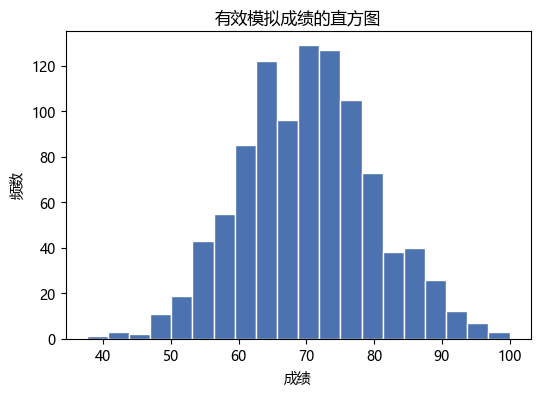

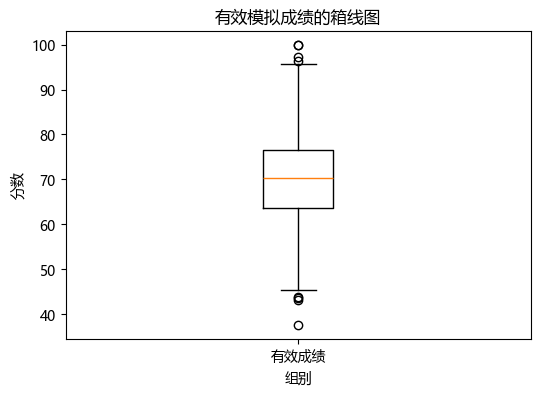

In [18]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

valid_scores = scores_nan[~np.isnan(scores_nan)]   # 实验2 的有效成绩

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(valid_scores, bins=20, color="#4C72B0", edgecolor="white")
ax.set_title("有效模拟成绩的直方图")
ax.set_xlabel("成绩")
ax.set_ylabel("频数")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(valid_scores)
ax.set_title("有效模拟成绩的箱线图")
ax.set_xlabel("组别")
ax.set_ylabel("分数")
ax.set_xticks([1])
ax.set_xticklabels(["有效成绩"])
plt.show()

直方图显示成绩近似正态、集中在 70 分附近；箱线图的中位数与四分位距和直方图一致，被截断到 0 或 100 的样本可能成为离群点。

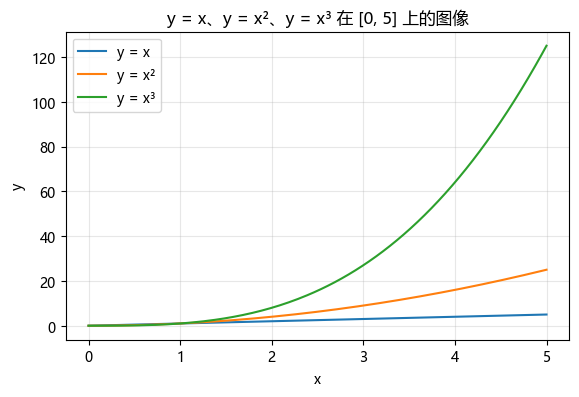

In [19]:
x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(x, x, label="y = x")
ax.plot(x, x ** 2, label="y = x²")
ax.plot(x, x ** 3, label="y = x³")
ax.set_title("y = x、y = x²、y = x³ 在 [0, 5] 上的图像")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

实验2 的 `scores_table` 还在内存中，可直接复用：pandas 的统计函数默认 `skipna=True`，与 NumPy 的 `np.mean` 行为不同。

In [20]:
print("实验2 的 scores_table 形状：", scores_table.shape)
print("pandas 求均值（自动跳过 NaN）：", scores_table["成绩"].mean())

实验2 的 scores_table 形状： (1000, 2)
pandas 求均值（自动跳过 NaN）： 70.19620743160239


### 任务1：创建 DataFrame

以姓名为行索引，新增 `Total`（三科总分）和 `Average`（三科平均分）两列。

In [21]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前 3 行：\n", df.head(3))
print("\n基本统计信息：\n", df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


### 任务2：`loc` 与 `iloc`

`loc` 按**标签**（姓名）取行，`iloc` 按**位置**（从 0 开始）取行；Carol 是第 3 行，所以对应 `iloc[2]`。

In [22]:
print("loc['Carol']：\n", df.loc["Carol"])
print("\niloc[2]（第 3 行）：\n", df.iloc[2])
print("\n平均分不低于 80 的学生：\n", df[df["Average"] >= 80])

loc['Carol']：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2]（第 3 行）：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


### 任务3：`mean(axis=0)` 与 `mean(axis=1)`

`axis=0` 沿行方向压缩，得到每科的列均值；`axis=1` 沿列方向压缩，得到每名学生的行均值。

In [23]:
print("三科列均值 mean(axis=0)：\n", df[["Math", "English", "Python"]].mean(axis=0))
print("\n每名学生行均值 mean(axis=1)：\n", df[["Math", "English", "Python"]].mean(axis=1))

三科列均值 mean(axis=0)：
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值 mean(axis=1)：
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


### 任务4：`apply`、`agg` 与 `rank`

In [24]:
df["Best"] = df[["Math", "English", "Python"]].apply(max, axis=1)
print("每名学生三科最高分：\n", df["Best"])

subject_stats = df[["Math", "English", "Python"]].agg(["min", "mean", "max"])
print("\n每科 min / mean / max：\n", subject_stats)

df["Math_rank"] = df["Math"].rank(ascending=False, method="min")
print("\n按 Math 排名（分数越高名次越靠前）：\n", df["Math_rank"])

每名学生三科最高分：
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Best, dtype: int64

每科 min / mean / max：
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按 Math 排名（分数越高名次越靠前）：
 Name
Alice    2.0
Bob      5.0
Carol    1.0
David    6.0
Eva      4.0
Frank    3.0
Name: Math_rank, dtype: float64


### 任务5：分组统计与 `transform`

In [25]:
grouped = df.groupby("Group")
print("每组人数：\n", grouped.size())
print("\n每组三科平均分：\n", grouped[["Math", "English", "Python"]].mean())

df["Group_Python_Mean"] = grouped["Python"].transform("mean")
print("\n所在组 Python 平均分：\n", df[["Group", "Python", "Group_Python_Mean"]])

每组人数：
 Group
A    3
B    3
dtype: int64

每组三科平均分：
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

所在组 Python 平均分：
       Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


### 任务6：`filter` 保留满足条件的组

A 组 Python 平均分为 87.00、B 组为 80.33，都 $\ge 80$，所以两组都被保留；若把阈值提高到 85，B 组就会被过滤掉。

In [26]:
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("保留的组：", kept["Group"].unique().tolist())
print("\n保留的学生：\n", kept[["Group", "Math", "English", "Python"]])

保留的组： ['A', 'B']

保留的学生：
       Group  Math  English  Python
Name                              
Alice     A    88       90      95
Bob       A    72       68      80
Carol     B    91       85      89
David     B    65       73      70
Eva       A    79       92      86
Frank     B    84       77      82


### 任务7：协方差与皮尔逊相关系数

协方差的正负表示两科是否同向变化，但数值大小受量纲影响；皮尔逊相关系数在 $[-1, 1]$ 内，绝对值越接近 1，线性关系越强。

In [27]:
score_cols = ["Math", "English", "Python"]
cov_mx = df[score_cols].cov()
corr_mx = df[score_cols].corr(method="pearson")

print("协方差矩阵：\n", cov_mx)
print("\n皮尔逊相关系数矩阵：\n", corr_mx)

协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


三科之间的协方差都为正、相关系数都在 $0.65 \sim 0.9$ 之间，说明成绩同向变化；其中 Math 与 Python 的相关性最强（约 $0.88$），Math 与 English 相对最弱（约 $0.65$）。协方差（如 Math–English 约 $62.6$）受分数单位和量级影响，只能看符号判断方向，强弱要用相关系数判断。